# 1.5 (2 dalis) — Perkeltinis mokymas ir dalinis bazės papildomas mokymas

**Pritaikyta iš kurso** [Transfer learning 2](https://colab.research.google.com/drive/1uDCip2CIMQN8bg859EZlOR_uWhHaLQNg). Taip pat remtasi oficialiu [TensorFlow perkeltinio mokymo vadovu](https://www.tensorflow.org/tutorials/images/transfer_learning).

**Ką daro originalas.** Ima ImageNet modelį be jo 1000 klasių galvutės, užšaldo bazę, moko naują klasifikavimo galvutę naujoms klasėms, tada atšildo dalį bazės ir su mažu mokymosi greičiu papildomai moko; vertina, išsaugo ir įkelia modelį.

**Kas pakeista.** Naudojami **tie patys 1.4 vaizdai, klasės ir ta pati testo aibė**, todėl rezultatus galima tiesiogiai palyginti su 1.4 CNN. Bazė — MobileNetV2 (ImageNet).


## Duomenys ir jų ryšys su klientu

Kliento katalogo kainynuose yra **vizualiai atpažįstamų laboratorinių reikmenų** (plastikiniai PCR ir pipetavimo reikmenys). Naudojamos trys klasės:

| Klasė | Kas tai | Atitikmuo kataloge |
|---|---|---|
| `antgaliai` | pipečių antgaliai, antgalių dėžutės / stoveliai | filtruoti antgaliai stoveliuose |
| `mikro_megintuvelis` | PCR mėgintuvėliai, 8 mėgintuvėlių juostelės, 1,5 ml mikromėgintuvėliai | PCR mėgintuvėliai ir juostelės |
| `mikroplokstele` | 96 / 384 / 24 / 6 šulinėlių plokštelės | PCR plokštelės, mikroplokštelės |

**Kilmė.** Tai **viešos nuotraukos iš Wikimedia Commons ir Openverse (Flickr ir kt.)**, ne kliento ir ne studento darytos. Kiekviena nuotrauka rankiniu būdu peržiūrėta; atmesti piešiniai, įranga ir scenos, kur daiktas nepagrindinis. Licencijos (CC0, viešas naudojimas, CC BY, CC BY-SA, CC BY-NC / NC-SA) ir autoriai išsaugoti `metadata.csv`; CC BY / BY-SA reikalauja nurodyti autorių pristatyme.

**Padalijimas.** Visos vieno autoriaus nuotraukos patenka į tą pačią `train` / `val` / `test` aibę, kad tos pačios fotosesijos ar fono kadrai nebūtų ir mokyme, ir teste.

**Paskirtis ir ribos.** Tai **pagalbinė katalogo / sandėlio prekių grupavimo užduotis**, ne pirkimų dokumentų analizė. Iš nuotraukos negalima nustatyti tūrio, sterilumo, gamintojo ar SKU. Rinkinys mažas, todėl rezultatai turi didelę paklaidą.


## 1. Tie patys duomenys kaip 1.4

MobileNetV2 tinka 160 × 160 įvestis. Testo aibė ta pati, tik vaizdai sumažinami iki kito dydžio.


In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

SEED = 42
tf.keras.utils.set_random_seed(SEED)
PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_ROOT = Path(os.getenv("TENDER_FIT_IMAGES_DIR", PROJECT / "private" / "1_4_vaizdai" / "galutinis"))
CLASS_NAMES = ["antgaliai", "mikro_megintuvelis", "mikroplokstele"]
assert DATA_ROOT.exists(), f"Nerastas {DATA_ROOT}"
for split in ("train", "val", "test"):
    counts = {c: len(list((DATA_ROOT / split / c).glob("*.jpg"))) for c in CLASS_NAMES}
    print(f"{split:5}", counts, "iš viso", sum(counts.values()))
print("TensorFlow", tf.__version__)

IMAGE_SIZE = (160, 160)
BATCH_SIZE = 16

def image_split(name, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        DATA_ROOT / name, labels="inferred", label_mode="int", class_names=CLASS_NAMES,
        image_size=IMAGE_SIZE, batch_size=BATCH_SIZE, shuffle=shuffle, seed=SEED if shuffle else None,
        crop_to_aspect_ratio=True)

train_ds = image_split("train", True).prefetch(tf.data.AUTOTUNE)
val_ds = image_split("val", False).prefetch(tf.data.AUTOTUNE)
test_ds = image_split("test", False).prefetch(tf.data.AUTOTUNE)
y_test = np.concatenate([y.numpy() for _, y in test_ds])


train {'antgaliai': 41, 'mikro_megintuvelis': 34, 'mikroplokstele': 54} iš viso 129
val   {'antgaliai': 9, 'mikro_megintuvelis': 8, 'mikroplokstele': 12} iš viso 29
test  {'antgaliai': 13, 'mikro_megintuvelis': 10, 'mikroplokstele': 16} iš viso 39
TensorFlow 2.19.0
Found 129 files belonging to 3 classes.


Found 29 files belonging to 3 classes.


Found 39 files belonging to 3 classes.


## 2. Užšaldyta iš anksto išmokyta bazė + nauja galvutė

`include_top=False` pašalina ImageNet galvutę. `base.trainable = False` — bazės svoriai nekeičiami. `preprocess_input` perskaičiuoja pikselius į MobileNetV2 tikėtiną intervalą. Mokomas tik `Dense(3)` sluoksnis.


In [2]:
from tensorflow.keras import layers

base = tf.keras.applications.MobileNetV2(input_shape=(*IMAGE_SIZE, 3), include_top=False, weights="imagenet")
base.trainable = False
augment = tf.keras.Sequential([layers.RandomFlip("horizontal_and_vertical"), layers.RandomRotation(0.15),
                               layers.RandomZoom(0.15)], name="augmentacija")
inputs = tf.keras.Input(shape=(*IMAGE_SIZE, 3))
x = augment(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(CLASS_NAMES), activation="softmax")(x)
model = tf.keras.Model(inputs, outputs, name="mobilenetv2_reikmenys")
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
print(f"Mokomų parametrų: {trainable:,} iš {model.count_params():,}")


Mokomų parametrų: 3,843 iš 2,261,827


## 3. Mokyti naują galvutę


In [3]:
head_history = model.fit(train_ds, validation_data=val_ds, epochs=40, verbose=0,
                         callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)])
h1 = pd.DataFrame(head_history.history)
print("Epochų:", len(h1), "| geriausias val_accuracy:", round(h1.val_accuracy.max(), 3))


<venv>/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epochų: 33 | geriausias val_accuracy: 0.828


In [4]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

def evaluate(model, name):
    probs = model.predict(test_ds, verbose=0)
    pred = probs.argmax(axis=1)
    print(f"== {name}: testo tikslumas {accuracy_score(y_test, pred):.3f} ({(pred == y_test).sum()}/{len(y_test)})")
    print(classification_report(y_test, pred, target_names=CLASS_NAMES, zero_division=0))
    cm = confusion_matrix(y_test, pred)
    print("Painiavos matrica (eilutės = tikra, stulpeliai = prognozė):\n", pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES))
    return pred

def show_mistakes(pred, title, limit=8):
    images = np.concatenate([x.numpy() for x, _ in test_ds])
    wrong = np.where(pred != y_test)[0][:limit]
    if len(wrong) == 0:
        print("Klaidų nėra."); return
    plt.figure(figsize=(3 * len(wrong), 3.4))
    for k, i in enumerate(wrong):
        plt.subplot(1, len(wrong), k + 1)
        plt.imshow(images[i].astype("uint8")); plt.axis("off")
        plt.title(f"tikra: {CLASS_NAMES[y_test[i]]}\nprognozė: {CLASS_NAMES[pred[i]]}", fontsize=8)
    plt.suptitle(title); plt.tight_layout(); plt.show()

head_pred = evaluate(model, "Užšaldyta bazė + nauja galvutė")


== Užšaldyta bazė + nauja galvutė: testo tikslumas 0.795 (31/39)
                    precision    recall  f1-score   support

         antgaliai       0.80      0.62      0.70        13
mikro_megintuvelis       0.82      0.90      0.86        10
    mikroplokstele       0.78      0.88      0.82        16

          accuracy                           0.79        39
         macro avg       0.80      0.80      0.79        39
      weighted avg       0.80      0.79      0.79        39

Painiavos matrica (eilutės = tikra, stulpeliai = prognozė):
                     antgaliai  mikro_megintuvelis  mikroplokstele
antgaliai                   8                   1               4
mikro_megintuvelis          1                   9               0
mikroplokstele              1                   1              14


## 4. Atsargiai papildomai mokyti paskutinę bazės dalį

Atšildomi tik paskutiniai 30 MobileNetV2 sluoksnių, `BatchNormalization` sluoksniai lieka užšaldyti (mažos partijos gali sugadinti jų statistiką), mokymosi greitis sumažinamas 100 kartų. Validavimo aibė lemia sustojimą; testo aibė vis dar nenaudojama.


Mokomų parametrų po atšildymo: 1,514,563


<venv>/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


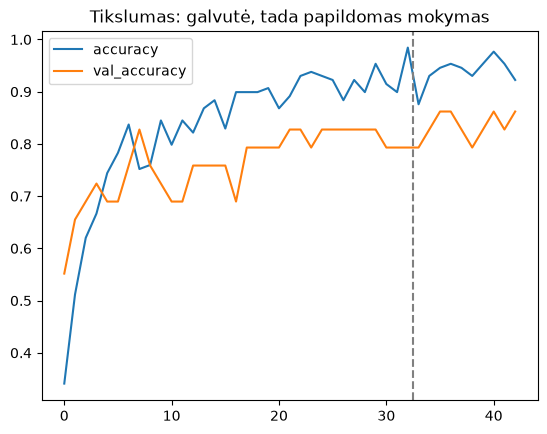

In [5]:
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
model.compile(optimizer=tf.keras.optimizers.Adam(1e-5), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
print(f"Mokomų parametrų po atšildymo: {trainable:,}")
fine_history = model.fit(train_ds, validation_data=val_ds, epochs=30, verbose=0,
                         callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True)])
h2 = pd.DataFrame(fine_history.history)
h = pd.concat([h1, h2], ignore_index=True)
ax = h[["accuracy", "val_accuracy"]].plot(title="Tikslumas: galvutė, tada papildomas mokymas")
ax.axvline(len(h1) - 0.5, color="grey", ls="--"); plt.show()


## 5. Galutinis įvertinimas ir palyginimas su 1.4 CNN


== Po papildomo mokymo: testo tikslumas 0.744 (29/39)
                    precision    recall  f1-score   support

         antgaliai       0.75      0.46      0.57        13
mikro_megintuvelis       0.75      0.90      0.82        10
    mikroplokstele       0.74      0.88      0.80        16

          accuracy                           0.74        39
         macro avg       0.75      0.75      0.73        39
      weighted avg       0.74      0.74      0.73        39

Painiavos matrica (eilutės = tikra, stulpeliai = prognozė):
                     antgaliai  mikro_megintuvelis  mikroplokstele
antgaliai                   6                   2               5
mikro_megintuvelis          1                   9               0
mikroplokstele              1                   1              14


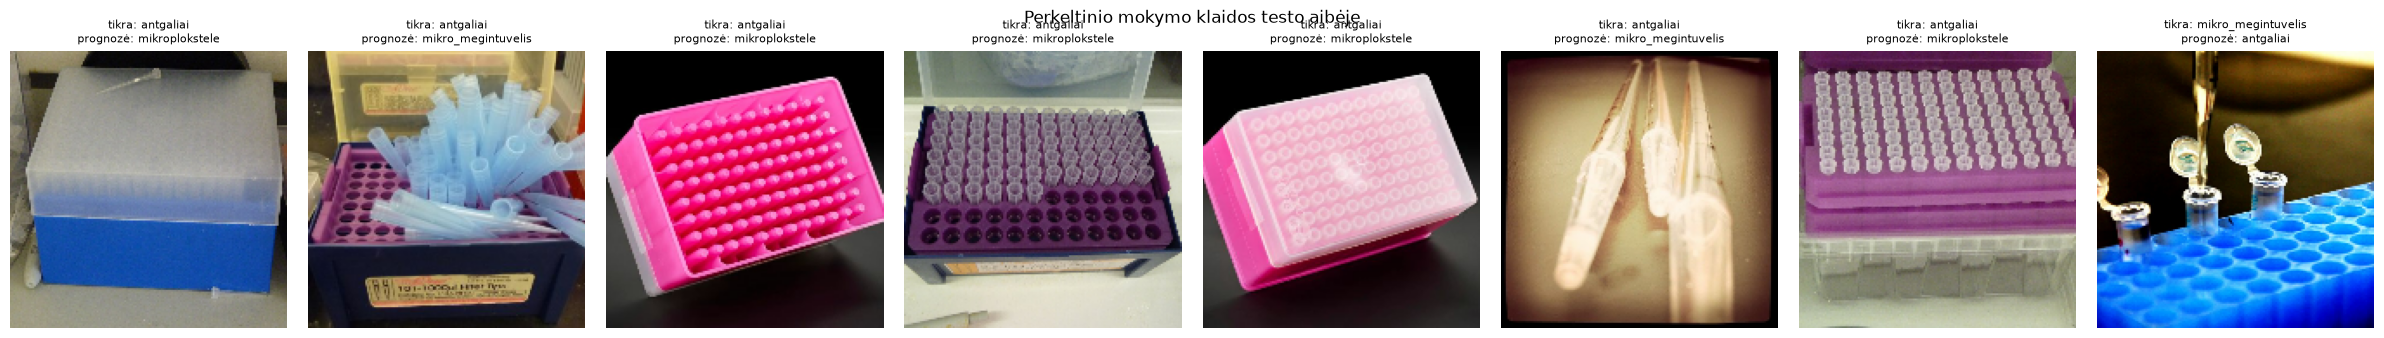

,modelis,testo tikslumas
0,1.4 MLP,0.256
1,1.4 CNN nuo nulio,0.359
2,Perkeltinis: tik galvutė,0.795
3,Perkeltinis: + papildomas mokymas,0.744


In [6]:
fine_pred = evaluate(model, "Po papildomo mokymo")
show_mistakes(fine_pred, "Perkeltinio mokymo klaidos testo aibėje")
cnn_file = PROJECT / "private" / "rezultatai" / "1_4_cnn_test.csv"
rows = [{"modelis": "Perkeltinis: tik galvutė", "testo tikslumas": (head_pred == y_test).mean()},
        {"modelis": "Perkeltinis: + papildomas mokymas", "testo tikslumas": (fine_pred == y_test).mean()}]
if cnn_file.exists():
    cnn = pd.read_csv(cnn_file)
    assert (cnn.y.values == y_test).all(), "1.4 ir 1.5 testo aibės nesutampa"
    rows = [{"modelis": "1.4 MLP", "testo tikslumas": (cnn.mlp == cnn.y).mean()},
            {"modelis": "1.4 CNN nuo nulio", "testo tikslumas": (cnn.cnn == cnn.y).mean()}] + rows
pd.DataFrame(rows).round(3)


## 6. Išsaugoti ir iš naujo įkelti


In [7]:
path = PROJECT / "private" / "modeliai" / "1_5_reikmenu_mobilenetv2.keras"
path.parent.mkdir(exist_ok=True)
model.save(path)
reloaded = tf.keras.models.load_model(path)
batch, labels = next(iter(test_ds))
print("Įkeltas modelis:", CLASS_NAMES[int(reloaded.predict(batch[:1], verbose=0).argmax())], "| tikra:", CLASS_NAMES[int(labels[0])])


Įkeltas modelis: mikroplokstele | tikra: antgaliai


## 7. Išvados

Interpretacija — pristatymo gide (`docs/1_3_1_5_pristatymo_gidas.md`).
